## Task 2 N-shot ICL — Non-COVID Pneumonia vs COVID-19
Few-shot in-context learning with Gemma-3-4b on A100.

---


### Quick Setup Instructions
* Run the installation cell below **once**.
* Click **"Restart session"** when it completes.
* Do not re-run install after restart.


In [1]:
import os
# Check if running in a Colab environment with GPU
if "COLAB_GPU" in os.environ:
    # Use unsloth[colab-new] for Colab to handle all dependencies.
    # This ensures compatible versions of bitsandbytes, accelerate, xformers, peft, trl, transformers etc.
    !pip install "unsloth[colab-new]==2026.1.3"
else:
    # For non-Colab environments or if no GPU, install basic unsloth.
    !pip install "unsloth==2026.1.3"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.7 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of diffusers to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 63.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 134.1 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 98.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### Model Loading


In [2]:
from unsloth import FastVisionModel # FastLanguageModel for LLMs
import torch

model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-3-4b-it",
    load_in_4bit = True, # Use 4bit to reduce memory use. False for 16bit LoRA.
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for long context
)
from unsloth import get_chat_template

processor = get_chat_template(
    processor,
    "gemma-3"
)


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.1.3: Fast Gemma3 patching. Transformers: 4.57.3.
   \\   /|    NVIDIA A100-SXM4-80GB. Num GPUs = 1. Max memory: 79.251 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 8.0. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Gemma3 does not support SDPA - switching to fast eager.


model.safetensors:   0%|          | 0.00/4.56G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

### Dataset + Seeded Exemplar Setup + Results Helper


In [3]:
from datasets import load_dataset
from pathlib import Path
import pandas as pd
import re
import random
import torch

SEED = 3407
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATASET_ID = "Henryayay/POLCOVID_task2_70_10_20"
test_ds = load_dataset(DATASET_ID, split="test")
train_ds = load_dataset(DATASET_ID, split="train")

LABEL_MAP = {0: "Non-COVID Pneumonia", 1: "COVID-19"}
NAME_TO_ID = {"Non-COVID Pneumonia": 0, "COVID-19": 1}

TASK_ID = "Task2_nshot"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "ICL" / "Task2"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

def record_and_save_run(y_true, y_pred, setup, model, accuracy_pct, task_id=TASK_ID, trigger_download=True):
    """Save predictions under Results/<method>/<task>/ with task, setup, model, and accuracy in the filename."""
    name_to_id = NAME_TO_ID
    y_true = list(y_true)
    y_pred = list(y_pred)
    df = pd.DataFrame({
        "Index": range(len(y_true)),
        "True_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_true],
        "Predicted_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_pred],
        "True_Label_Name": y_true,
        "Predicted_Label_Name": y_pred,
    })

    meta = {
        "task_id": task_id,
        "setup": setup,
        "model": model,
        "accuracy_pct": float(accuracy_pct),
        "y_true": y_true,
        "y_pred": y_pred,
    }
    global RUN_META
    RUN_META = meta
    history = list(globals().get("RUN_HISTORY", []))
    key = (task_id, setup, model)
    history = [r for r in history if (r["task_id"], r["setup"], r["model"]) != key]
    history.append(meta)
    globals()["RUN_HISTORY"] = history

    acc_label = f"{float(accuracy_pct):.2f}pct"
    filename = f"{_slug(task_id)}_{_slug(setup)}_{_slug(model)}_acc{acc_label}.csv"

    dest_dir = None
    for candidate in (LOCAL_RESULTS_ROOT, Path.cwd() / "Results" / "ICL" / "Task2"):
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok", encoding="utf-8")
            probe.unlink()
            dest_dir = candidate
            break
        except Exception:
            continue
    if dest_dir is None:
        dest_dir = Path.cwd() / "Results" / "ICL" / "Task2"
        dest_dir.mkdir(parents=True, exist_ok=True)

    dest_path = dest_dir / filename
    df.to_csv(dest_path, index=False)
    print(f"Saved predictions to: {dest_path}")

    errors = df[df["Predicted_Label_ID"] == -1]
    if len(errors) > 0:
        print(f"WARNING: {len(errors)} predictions could not be mapped to IDs!")
        print(errors["Predicted_Label_Name"].unique())
    else:
        print("Verification Passed: All predictions mapped correctly.")

    saved_on_pc = str(LOCAL_RESULTS_ROOT) in str(dest_path)
    if trigger_download and not saved_on_pc:
        cwd_copy = Path.cwd() / filename
        if cwd_copy.resolve() != dest_path.resolve():
            df.to_csv(cwd_copy, index=False)
        try:
            from google.colab import files
            print(f"Starting download for {filename}")
            files.download(str(cwd_copy if cwd_copy.exists() else dest_path))
        except Exception as exc:
            print(f"Could not auto-download to your PC ({exc}). Copy this file to:\n{LOCAL_RESULTS_ROOT}")
    return dest_path


README.md:   0%|          | 0.00/624 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/303M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/43.2M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/87.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1596 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/228 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/456 [00:00<?, ? examples/s]

### N-shot Evaluation (sequential multi-image prompts)
Shot sizes: 2/4/6/8/10. Exemplar sampling uses `SEED=3407`. Batched eval is not used here because each prompt contains multiple exemplar images.


Running 2-shot evaluation (SEED=3407)


2-shot: 100%|██████████| 456/456 [07:13<00:00,  1.05it/s]


2-shot Accuracy: 54.61%
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.66      0.19      0.30       228
           COVID-19       0.53      0.90      0.66       228

           accuracy                           0.55       456
          macro avg       0.59      0.55      0.48       456
       weighted avg       0.59      0.55      0.48       456



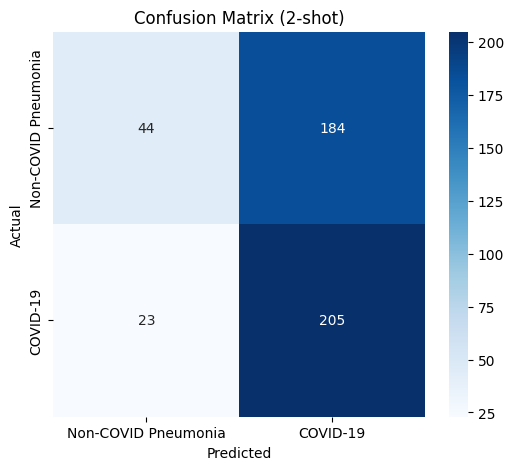

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_nshot_2shot_gemma-3-4b-it_acc54.61pct.csv
Verification Passed: All predictions mapped correctly.
Running 4-shot evaluation (SEED=3407)


4-shot: 100%|██████████| 456/456 [08:38<00:00,  1.14s/it]


4-shot Accuracy: 52.85%
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.52      0.93      0.66       228
           COVID-19       0.64      0.13      0.21       228

           accuracy                           0.53       456
          macro avg       0.58      0.53      0.44       456
       weighted avg       0.58      0.53      0.44       456



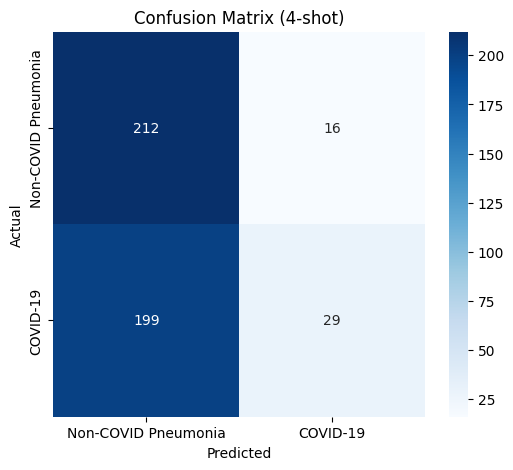

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_nshot_4shot_gemma-3-4b-it_acc52.85pct.csv
Verification Passed: All predictions mapped correctly.
Running 6-shot evaluation (SEED=3407)


6-shot: 100%|██████████| 456/456 [10:23<00:00,  1.37s/it]


6-shot Accuracy: 50.00%
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.50      0.99      0.66       228
           COVID-19       0.50      0.01      0.02       228

           accuracy                           0.50       456
          macro avg       0.50      0.50      0.34       456
       weighted avg       0.50      0.50      0.34       456



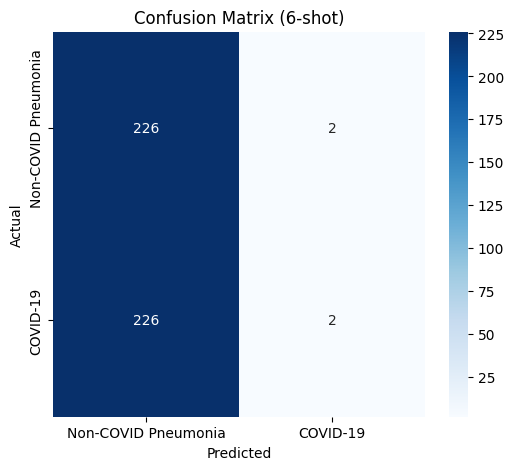

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_nshot_6shot_gemma-3-4b-it_acc50.00pct.csv
Verification Passed: All predictions mapped correctly.
Running 8-shot evaluation (SEED=3407)


8-shot: 100%|██████████| 456/456 [12:15<00:00,  1.61s/it]


8-shot Accuracy: 50.00%
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.50      1.00      0.67       228
           COVID-19       0.00      0.00      0.00       228

           accuracy                           0.50       456
          macro avg       0.25      0.50      0.33       456
       weighted avg       0.25      0.50      0.33       456




/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


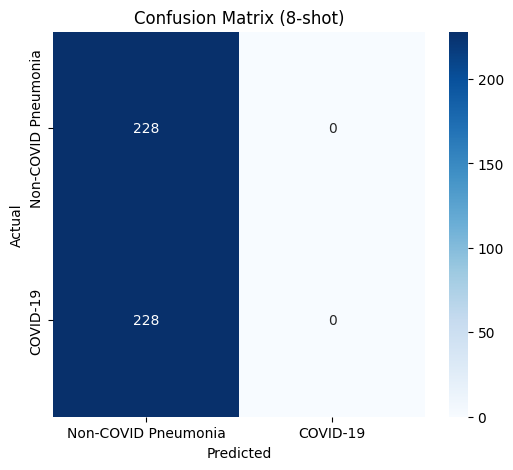

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_nshot_8shot_gemma-3-4b-it_acc50.00pct.csv
Verification Passed: All predictions mapped correctly.
Running 10-shot evaluation (SEED=3407)


10-shot: 100%|██████████| 456/456 [14:16<00:00,  1.88s/it]


10-shot Accuracy: 50.22%
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.50      1.00      0.67       228
           COVID-19       1.00      0.00      0.01       228

           accuracy                           0.50       456
          macro avg       0.75      0.50      0.34       456
       weighted avg       0.75      0.50      0.34       456



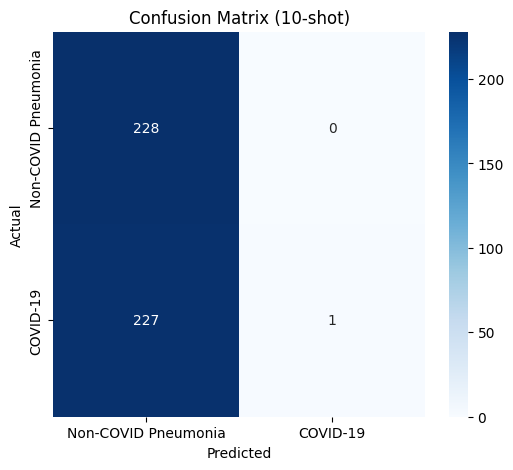

Saved predictions to: C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results/ICL/Task2/Task2_nshot_10shot_gemma-3-4b-it_acc50.22pct.csv
Verification Passed: All predictions mapped correctly.


In [4]:
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from unsloth import FastVisionModel
import torch
import random

FastVisionModel.for_inference(model)

SHOT_SIZES = [2, 4, 6, 8, 10]  # total shots (balanced per class)

def sample_exemplars(train_ds, total_shots, seed):
    """Balanced few-shot sampling. total_shots must be even."""
    rng = random.Random(seed)
    shots_per_class = total_shots // 2
    # 0 for Non-COVID Pneumonia, 1 for COVID-19
    class0_indices = [i for i, x in enumerate(train_ds) if x["label"] == 0]
    class1_indices = [i for i, x in enumerate(train_ds) if x["label"] == 1]
    selected_0 = rng.sample(class0_indices, shots_per_class)
    selected_1 = rng.sample(class1_indices, shots_per_class)
    all_indices = [(idx, "Non-COVID Pneumonia") for idx in selected_0] + [(idx, "COVID-19") for idx in selected_1]
    rng.shuffle(all_indices)
    return all_indices

def build_content(exemplars, query_image):
    content = []
    for idx, label_name in exemplars:
        content.append({"type": "text", "text": f"Example ({label_name}):"})
        content.append({"type": "image"})
        content.append({"type": "text", "text": f"Label: {label_name}"})
    content.append({
        "type": "text",
        "text": "\n--- TASK ---\nAnalyze the FINAL X-ray below based on the visual patterns shown in the examples above. Classify it as 'Non-COVID Pneumonia' or 'COVID-19'. Output ONLY the diagnosis.\nFinal Image:"
    })
    content.append({"type": "image"})
    images = [train_ds[idx]["image"] for idx, _ in exemplars] + [query_image]
    return content, images

def parse_response(response):
    # Check longer/more specific label first
    if "COVID-19" in response:
        return "COVID-19"
    if "Non-COVID Pneumonia" in response:
        return "Non-COVID Pneumonia"
    return "Error"

for total_shots in SHOT_SIZES:
    print("=" * 60)
    print(f"Running {total_shots}-shot evaluation (SEED={SEED})")
    print("=" * 60)

    # Deterministic per-shot seed derived from shared SEED
    exemplars = sample_exemplars(train_ds, total_shots, seed=SEED + total_shots)

    y_true, y_pred = [], []
    for sample in tqdm(test_ds, desc=f"{total_shots}-shot"):
        actual = LABEL_MAP[sample["label"]]
        y_true.append(actual)

        content, images = build_content(exemplars, sample["image"])
        messages = [{"role": "user", "content": content}]
        input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
        inputs = processor(
            text=input_text,
            images=images,
            return_tensors="pt",
            padding=True,
        ).to("cuda")

        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=15,
                temperature=0.01,
                use_cache=True,
            )
        response = processor.decode(output[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)
        y_pred.append(parse_response(response))

    acc = accuracy_score(y_true, y_pred) * 100
    print(f"\n{total_shots}-shot Accuracy: {acc:.2f}%")
    print(classification_report(y_true, y_pred, labels=["Non-COVID Pneumonia", "COVID-19"]))
    cm = confusion_matrix(y_true, y_pred, labels=["Non-COVID Pneumonia", "COVID-19"])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Non-COVID Pneumonia", "COVID-19"],
                yticklabels=["Non-COVID Pneumonia", "COVID-19"])
    plt.title(f"Confusion Matrix ({total_shots}-shot)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    record_and_save_run(
        y_true,
        y_pred,
        setup=f"{total_shots}shot",
        model="gemma-3-4b-it",
        accuracy_pct=acc,
    )
